# Simulating the uncertainty of sample correlation estimator

Assume that we want to examine the properties of the sample covariance estimator, in particular we want to look at the distribution of the correlations. We assume the correlation matrix $\boldsymbol{C}$

$$
\boldsymbol{C} = \begin{pmatrix} 1 & \rho & \rho  & \rho & \rho \\
\rho & 1 & \rho  & \rho & \rho \\
\rho & \rho & 1  & \rho & \rho \\
\rho & \rho & \rho  & 1 & \rho \\
\rho & \rho & \rho  & \rho & 1 \end{pmatrix}
$$

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

## Problem 1

Assume $\rho = 0.5$ and that the data generating process is normal 

$$
\mathbf{X} \sim N(\mathbf{0}, \boldsymbol{C})
$$

Simulate $N=25$ observations $10\;000$ times and plot the histogram of the correlation estimates for the first and second variable. 


### Solution

mean 0.491, std 0.157, skew -0.54
2.5% and 97.5% percentiles: [0.147 0.75 ]


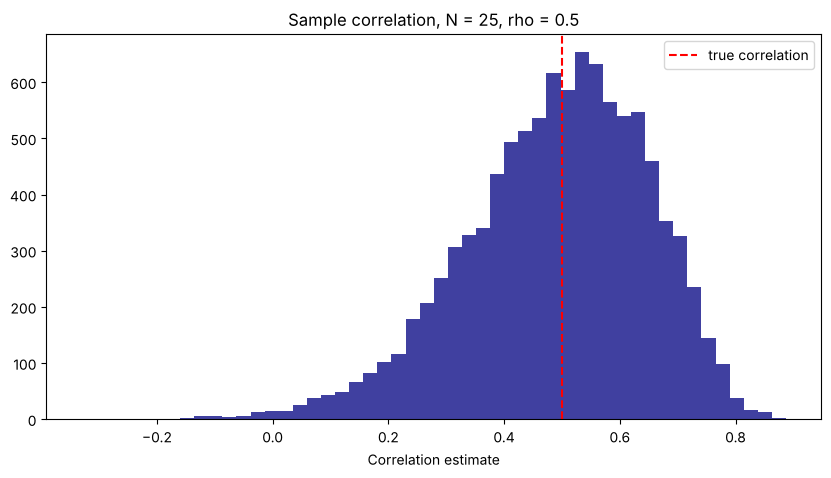

In [2]:
def simulate_corr(rho, num_obs=25, num_sim=10_000, num_var=5, seed=1):
    """simulate num_sim samples of num_obs observations and return the estimated correlation between variable 1 and 2"""
    rng = np.random.default_rng(seed)
    corr = np.full((num_var, num_var), rho)
    np.fill_diagonal(corr, 1.0)
    data = rng.multivariate_normal(np.zeros(num_var), corr, (num_sim, num_obs))
    return np.array([np.corrcoef(d[:, 0], d[:, 1])[0, 1] for d in data])

rho_hat = simulate_corr(0.5)
print(f'mean {rho_hat.mean():.3f}, std {rho_hat.std():.3f}, skew {stats.skew(rho_hat):.2f}')
print('2.5% and 97.5% percentiles:', np.percentile(rho_hat, [2.5, 97.5]).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(rho_hat, bins=50, color='navy', alpha=0.75)
ax.axvline(0.5, color='red', linestyle='--', label='true correlation')
ax.set(xlabel='Correlation estimate', title='Sample correlation, N = 25, rho = 0.5'); ax.legend();

**Interpretation:** With only 25 observations a true correlation of 0.5 is estimated anywhere between about 0.15 and 0.75 (95% of the simulations). The estimator is centred close to 0.5 (slightly below – a small-sample bias) and is already left-skewed. Short samples give very noisy correlation estimates, which is a key source of estimation risk in portfolio optimization.

## Problem 2

What happens if we increase $\rho$?

### Solution

mean 0.896, std 0.042, skew -1.15


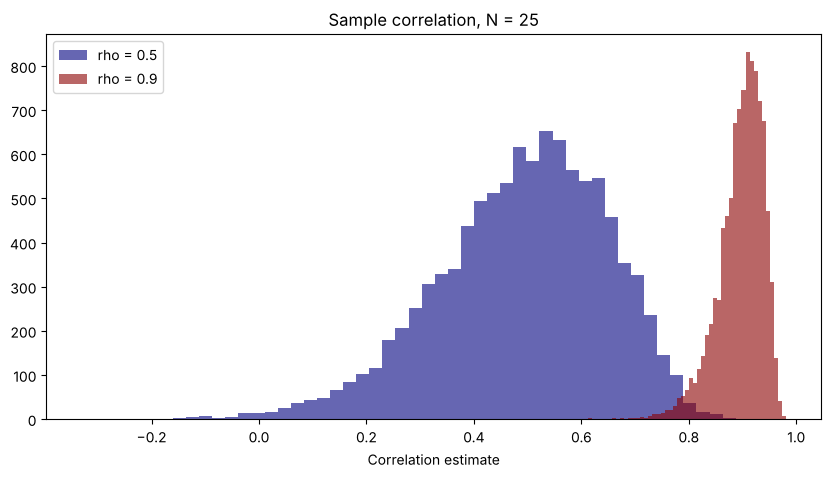

In [3]:
rho_hat_high = simulate_corr(0.9)
print(f'mean {rho_hat_high.mean():.3f}, std {rho_hat_high.std():.3f}, skew {stats.skew(rho_hat_high):.2f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(rho_hat, bins=50, color='navy', alpha=0.6, label='rho = 0.5')
ax.hist(rho_hat_high, bins=50, color='darkred', alpha=0.6, label='rho = 0.9')
ax.set(xlabel='Correlation estimate', title='Sample correlation, N = 25'); ax.legend();

**Interpretation:** With $\rho = 0.9$ the distribution is much narrower (std 0.04 vs 0.16), because the variance of $\hat{\rho}$ is roughly $(1-\rho^2)^2/N$, but it is strongly left-skewed (skewness about −1.2 vs −0.5): the estimate cannot exceed 1. Both cases are skewed – the effect is just much stronger close to the boundary.

## Problem 3

What happens if you apply the [Fisher transformation](https://en.wikipedia.org/wiki/Fisher_transformation) $z = \frac{1}{2} \ln \frac{1 + \hat{\rho}}{1 - \hat{\rho}} = \text{artanh}(\hat{\rho})$?

### Solution

rho = 0.5: std 0.212, skew 0.02
rho = 0.9: std 0.210, skew 0.01
theory: 1/sqrt(N-3) = 0.213


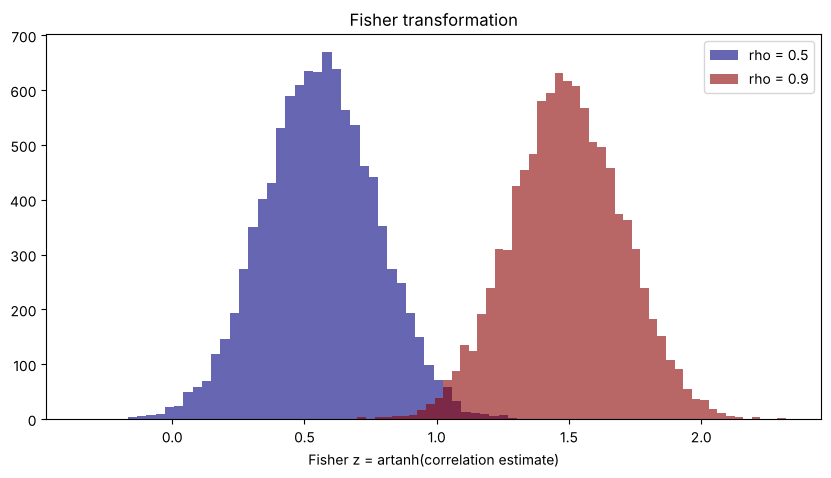

In [4]:
z_low, z_high = np.arctanh(rho_hat), np.arctanh(rho_hat_high)
print(f'rho = 0.5: std {z_low.std():.3f}, skew {stats.skew(z_low):.2f}')
print(f'rho = 0.9: std {z_high.std():.3f}, skew {stats.skew(z_high):.2f}')
print(f'theory: 1/sqrt(N-3) = {1/np.sqrt(22):.3f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(z_low, bins=50, color='navy', alpha=0.6, label='rho = 0.5')
ax.hist(z_high, bins=50, color='darkred', alpha=0.6, label='rho = 0.9')
ax.set(xlabel='Fisher z = artanh(correlation estimate)', title='Fisher transformation'); ax.legend();

**Interpretation:** After the Fisher transformation both distributions are symmetric and approximately normal with the **same** standard deviation $1/\sqrt{N-3} \approx 0.21$, whatever the true $\rho$: $z \overset{a}{\sim} N(\text{artanh}(\rho), 1/(N-3))$. This variance-stabilizing property is why confidence intervals for correlations are built on the $z$-scale and transformed back with $\tanh$.